# Chapter 13: Bargaining, Coalitions, and Cooperative Value

This notebook reruns four worked examples from the chapter: outside options in Nash bargaining, patience in Rubinstein's alternating offers, the Shapley value of a three-firm venture, and the Bondareva-Shapley test for a stable cost-sharing deal. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def nash_bargaining_linear(S, dS=0.0, dF=0.0):
    """Nash bargaining over a payment x to S's owner from a linear surplus S.

    Maximizes (x - dS)(S - x - dF): x = (S + dS - dF)/2, each gain (S - dS - dF)/2.
    Principle: nash-bargaining-solution. Book (ch013): S = 120 gives x = 60 and product 3,600;
    dS = 30 gives x = 75 and gains of 45 each.
    """
    x = (S + dS - dF) / 2
    gS, gF = x - dS, S - x - dF
    return {"x": x, "gain_S": gS, "gain_F": gF, "product": gS * gF}


def rubinstein_share(dU, dF):
    """First proposer's share in Rubinstein bargaining: (1 - dF) / (1 - dU dF).

    Principle: rubinstein-alternating-offers-result. Book (ch013): 0.90 and 0.90 give 0.10/0.19 =
    0.526316; dF = 0.80 gives 0.20/0.28 = 0.714286.
    """
    return (1 - dF) / (1 - dU * dF)


def shapley_value(v, players):
    """Shapley value by enumerating arrival orders.

    v maps a frozenset of players to its worth (missing coalitions are worth 0). Returns
    {"phi": {player: value}, "orders": [(order, {player: marginal contribution})]}.
    Principle: shapley-value. Book (ch013): v(AB) = 60, v(AC) = 20, v(BC) = 30, v(ABC) = 120 gives
    totals 260, 290, 170 over six orders and (130/3, 145/3, 85/3).
    """
    import itertools

    def worth(c):
        return v.get(frozenset(c), 0.0)
    orders, totals = [], {p: 0.0 for p in players}
    for order in itertools.permutations(players):
        seen, marg = [], {}
        for p in order:
            marg[p] = worth(seen + [p]) - worth(seen)
            totals[p] += marg[p]
            seen.append(p)
        orders.append((order, marg))
    n = len(orders)
    return {"phi": {p: totals[p] / n for p in players}, "totals": totals, "orders": orders}


def balanced_collection_check(values, weights, grand):
    """Weighted claim of a balanced collection against the grand coalition's worth.

    Returns (claim, holds) with holds = claim <= grand. Principle: bondareva-shapley-theorem.
    Book (ch013): weights 1/2 on three pairs worth 60 give 90 <= 100; pairs worth 70 give 105 > 100.
    """
    claim = sum(w * x for w, x in zip(weights, values))
    return claim, claim <= grand + 1e-12


def core_3player(pairs, grand):
    """Core of a three-player game with zero singletons and pair worths (v12, v13, v23).

    Nonempty iff grand >= each pair and grand >= (v12 + v13 + v23) / 2. Returns
    {"nonempty", "bound": half the pair sum, "equal_split", "pair_gets"}.
    Principle: bondareva-shapley-theorem. Book (ch013): pairs 60, grand 100: nonempty, equal split
    100/3 each and every pair gets 200/3 = 66.67 > 60; pairs 70 need at least 105.
    """
    bound = sum(pairs) / 2
    nonempty = grand >= max(pairs) - 1e-12 and grand >= bound - 1e-12
    return {"nonempty": nonempty, "bound": bound, "equal_split": grand / 3, "pair_gets": 2 * grand / 3}


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(nash_bargaining_linear=nash_bargaining_linear, rubinstein_share=rubinstein_share, shapley_value=shapley_value, balanced_collection_check=balanced_collection_check, core_3player=core_3player)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'nash-bargaining-solution': {'S': 120,
                              'x': 60,
                              'gains': (60, 60),
                              'product': 3600,
                              'dS': 30,
                              'x_dS': 75,
                              'gains_dS': (45, 45),
                              'options': ((80, 40), (40, 80)),
                              'option_product': 3200},
 'rubinstein-alternating-offers-result': {'surplus': 100000,
                                          'dU': 0.9,
                                          'dF': 0.9,
                                          'x': 0.526316,
                                          'union': 52631.58,
                                          'firm': 47368.42,
                                          'dF_alt': 0.8,
                                          'x_alt': 0.714286,
                                          'union_alt': 71428.57,
                                          'firm_alt': 28571.43,
                                          'rise': 18796.99},
 'shapley-value': {'v': {'AB': 60, 'AC': 20, 'BC': 30, 'ABC': 120},
                   'marginals': {'A': (0, 0, 60, 90, 20, 90),
                                 'B': (60, 100, 0, 0, 100, 30),
                                 'C': (60, 20, 60, 30, 0, 0)},
                   'totals': (260, 290, 170),
                   'phi': (43.333333333333336, 48.333333333333336, 28.333333333333332),
                   'phi_dummy': (30, 30, 0)},
 'bondareva-shapley-theorem': {'pair': 60,
                               'grand': 100,
                               'claim': 90,
                               'equal': 33.333333333333336,
                               'pair_gets': 66.66666666666667,
                               'pair_alt': 70,
                               'claim_alt': 105,
                               'sum_bound': 210},
 'constructed': {'nash-bargaining-solution': {'dS': [15, 45], 'dF': [30]},
                 'rubinstein-alternating-offers-result': {'dU': [0.8, 0.95], 'dF': [0.95]},
                 'shapley-value': {'grand': [100, 150]},
                 'bondareva-shapley-theorem': {'pair': [50, 66.66666666666667]}}}


def nash_picture(ds=0, df=0):
    r = games.nash_bargaining_linear(120, ds, df)
    xs = np.linspace(ds, 120 - df, 200)
    fig, ax = new_figure()
    ax.plot(xs, (xs - ds) * (120 - xs - df), color=PALETTE["navy"], linewidth=2.2,
            label=f"Nash product (x - {ds})(120 - x - {df})")
    mark(ax, r["x"], r["product"], f"x = {num(r['x'], 1)}, product {num(r['product'], 2)}", col="gold", dx=0, dy=-10,
         ha="center", va="top")
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 5_200)
    ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, 1.0))
    ax.set_xlabel("Payment x to the data supplier ($ thousand)")
    ax.set_ylabel("Nash product")
    metrics = {"Payment x": num(r["x"], 1), "Supplier gain over its option": num(r["gain_S"], 1),
               "Firm gain over its option": num(r["gain_F"], 1), "Nash product": num(r["product"], 2)}
    interp = (f"Maximize (x - {ds})(120 - x - {df}). The derivative is (120 - x - {df}) - (x - {ds}) = 0, so x = "
              f"(120 + {ds} - {df}) / 2 = {num(r['x'], 1)}. The supplier gains {num(r['x'], 1)} - {ds} = "
              f"{num(r['gain_S'], 1)} and the firm 120 - {num(r['x'], 1)} - {df} = {num(r['gain_F'], 1)}: the "
              f"surplus over the two options, {120 - ds - df}, is split equally.")
    steps = [f"x = (120 + {ds} - {df}) / 2 = {num(r['x'], 1)}", f"Supplier gain = {num(r['x'], 1)} - {ds} = {num(r['gain_S'], 1)}",
             f"Firm gain = 120 - {num(r['x'], 1)} - {df} = {num(r['gain_F'], 1)}",
             f"Product = {num(r['gain_S'], 1)} x {num(r['gain_F'], 1)} = {num(r['product'], 2)}"]
    alt = f"Nash product curve over the payment, peaking at x = {num(r['x'], 1)} with outside options {ds} and {df}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


DFS = [0.8, 0.9, 0.95]


def rubinstein_picture(du=0.9, dfirm=0.9):
    x = games.rubinstein_share(du, dfirm)
    union = 100_000 * x
    firm = 100_000 - union
    fig, (axL, axR) = new_figure(ncols=2)
    axL.bar([0], [union], color=PALETTE["teal"], width=0.5, label="union")
    axL.bar([0], [firm], bottom=[union], color=PALETTE["gold"], width=0.5, label="firm")
    label(axL, 0, union / 2, f"union {money(union)}", col="ink", dx=0, dy=0, ha="center", va="center")
    label(axL, 0, union + firm / 2, f"firm {money(firm)}", col="ink", dx=0, dy=0, ha="center", va="center")
    axL.set_xlim(-0.6, 0.6)
    axL.set_ylim(0, 100_000)
    axL.set_xticks([])
    axL.set_xlabel("Split of the 100,000 surplus")
    axL.set_ylabel("Dollars")
    grid = np.array([[games.rubinstein_share(a, b) for b in DFS] for a in DFS])
    axR.imshow(grid, cmap="Blues", vmin=0.2, vmax=1.0, origin="lower")
    for i, a in enumerate(DFS):
        for j, b in enumerate(DFS):
            axR.text(j, i, num(grid[i, j], 3), ha="center", va="center", fontsize=10.5,
                     color="white" if grid[i, j] > 0.7 else PALETTE["ink"])
    i0, j0 = DFS.index(du), DFS.index(dfirm)
    axR.add_patch(__import__("matplotlib").patches.Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False,
                                                             ec=PALETTE["terracotta"], lw=2.5))
    axR.set_xticks(range(3), [str(b) for b in DFS])
    axR.set_yticks(range(3), [str(a) for a in DFS])
    axR.set_xlabel("Firm discount factor")
    axR.set_ylabel("Union discount factor")
    axR.grid(False)
    cont = dfirm * (100_000 * games.rubinstein_share(dfirm, du))
    metrics = {"Union share": num(x, 6), "Union keeps": money(union), "Firm gets": money(firm),
               "Firm's value of rejecting": money(cont)}
    interp = (f"x = (1 - {dfirm}) / (1 - {du} x {dfirm}) = {num(1 - dfirm, 2)} / {num(1 - du * dfirm, 4)} = {num(x, 6)}. "
              f"The union keeps {money(union)} and offers {money(firm)}. If the firm rejects, it proposes tomorrow and "
              f"keeps its proposer share, worth {dfirm} x {money(100_000 * games.rubinstein_share(dfirm, du))} = "
              f"{money(cont)} today, the same as the offer, so it accepts at once.")
    steps = [f"du x df = {du} x {dfirm} = {num(du * dfirm, 4)}", f"x = {num(1 - dfirm, 2)} / {num(1 - du * dfirm, 4)} = {num(x, 6)}",
             f"Union = 100,000 x {num(x, 6)} = {money(union)}", f"Firm = 100,000 - {money(union)} = {money(firm)}"]
    alt = f"Split bar of the surplus and a grid of union shares; with factors {du} and {dfirm} the union keeps {money(union)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def venture(grand, game):
    if game == "dummy":
        return {frozenset("AB"): 60.0, frozenset("ABC"): 60.0}
    return {frozenset("AB"): 60.0, frozenset("AC"): 20.0, frozenset("BC"): 30.0, frozenset("ABC"): float(grand)}


def shapley_picture(grand=120, game="base"):
    v = venture(grand, game)
    res = games.shapley_value(v, "ABC")
    phi, tot = res["phi"], res["totals"]
    worth = v[frozenset("ABC")]
    fig, ax = new_figure()
    cols = [PALETTE["teal"], PALETTE["navy"], PALETTE["gold"]]
    ax.bar(range(3), [phi[p] for p in "ABC"], color=cols, width=0.6)
    for i, p in enumerate("ABC"):
        ax.annotate(num(phi[p], 2), (i, phi[p]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
    ax.set_xticks(range(3), ["A producer", "B storage", "C retailer"])
    ax.set_ylim(0, 70)
    ax.set_xlabel(f"Shares of v(ABC) = {num(worth, 0)} ($ thousand)")
    ax.set_ylabel("Shapley value")
    marg = {p: ", ".join(num(m[p], 0) for _, m in res["orders"]) for p in "ABC"}
    if game == "dummy":
        note = (f" C adds nothing to any coalition, so it gets 0 and A and B split 60. The grand-coalition control "
                f"does not apply here, because C's arrival adds nothing.")
    else:
        note = ""
    metrics = {"A": num(phi["A"], 2), "B": num(phi["B"], 2), "C": num(phi["C"], 2),
               "Sum": num(sum(phi.values()), 2), "Totals over six orders (A, B, C)":
               f"{num(tot['A'], 0)}, {num(tot['B'], 0)}, {num(tot['C'], 0)}"}
    interp = (f"Over the six arrival orders A adds {marg['A']} (total {num(tot['A'], 0)}), B adds {marg['B']} (total "
              f"{num(tot['B'], 0)}) and C adds {marg['C']} (total {num(tot['C'], 0)}). Dividing by six gives "
              f"{num(phi['A'], 2)}, {num(phi['B'], 2)} and {num(phi['C'], 2)}; the exact shares sum to "
              f"({num(tot['A'], 0)} + {num(tot['B'], 0)} + {num(tot['C'], 0)}) / 6 = {num(worth, 0)}." + note)
    steps = [f"A: {num(tot['A'], 0)} / 6 = {num(phi['A'], 2)}", f"B: {num(tot['B'], 0)} / 6 = {num(phi['B'], 2)}",
             f"C: {num(tot['C'], 0)} / 6 = {num(phi['C'], 2)}",
             f"Check: ({num(tot['A'], 0)} + {num(tot['B'], 0)} + {num(tot['C'], 0)}) / 6 = {num(worth, 0)}"]
    alt = (f"Bars of Shapley values: A {num(phi['A'], 2)}, B {num(phi['B'], 2)}, C {num(phi['C'], 2)}, summing to "
           f"{num(worth, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def core_picture(pair=60):
    claim, holds = games.balanced_collection_check([pair] * 3, [0.5] * 3, 100)
    core = games.core_3player((pair, pair, pair), 100)
    fig, ax = new_figure()
    ax.bar([0, 1], [claim, 100], width=0.5, color=[PALETTE["gold"] if holds else PALETTE["terracotta"], PALETTE["teal"]])
    for x, v in zip([0, 1], [claim, 100]):
        ax.annotate(num(v, 2), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
    ax.set_xticks([0, 1], ["weighted pair claim\n0.5 x (3 pairs)", "grand coalition\nv(ABC)"])
    ax.set_ylim(0, 125)
    ax.set_xlabel("Hospital cost-sharing")
    ax.set_ylabel("Saving")
    pair_txt = "200/3" if abs(pair - 200 / 3) < 1e-9 else num(pair, 0)
    exact = abs(claim - 100) < 1e-9
    if exact:
        verdict = ("The claim equals 100 exactly, so the core is a single point: 100/3 = 33.33 each, giving every "
                   "pair exactly its 66.67.")
    elif holds:
        verdict = (f"The claim is within 100, so the core is nonempty: the equal split 33.33 each gives every pair "
                   f"66.67, more than {pair_txt}.")
    else:
        verdict = (f"The claim exceeds 100, so the core is empty: adding the pair constraints needs a total of at "
                   f"least {num(2 * core['bound'] / 2, 2)} = 3 x {pair_txt} / 2, more than 100.")
    metrics = {"Weighted claim": num(claim, 2), "Grand coalition": "100", "Core": "nonempty" if holds else "empty",
               "Equal split": num(core["equal_split"], 2), "Each pair gets under equal split": num(core["pair_gets"], 2)}
    interp = f"With weight 1/2 on each pair the claim is 0.5 x {pair_txt} x 3 = {num(claim, 2)} against 100. {verdict}"
    steps = [f"Claim = 0.5 x {pair_txt} + 0.5 x {pair_txt} + 0.5 x {pair_txt} = {num(claim, 2)}",
             f"Balanced: {num(claim, 2)} {'<=' if holds else '>'} 100", "Core " + ("nonempty" if holds else "empty")]
    alt = f"Bars of the weighted pair claim {num(claim, 2)} against the grand coalition's 100."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Nash bargaining solution: outside options

$$N(x)=x(120-x), \qquad N'(x)=120-2x=0, \qquad N_1(x)=(x-30)(120-x)$$

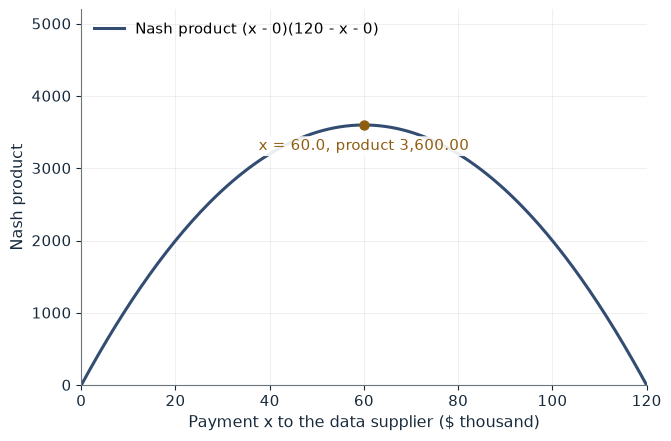

Payment x                      60.0
Supplier gain over its option  60.0
Firm gain over its option      60.0
Nash product                   3,600.00

Worked steps:
  1. x = (120 + 0 - 0) / 2 = 60.0
  2. Supplier gain = 60.0 - 0 = 60.0
  3. Firm gain = 120 - 60.0 - 0 = 60.0
  4. Product = 60.0 x 60.0 = 3,600.00

Maximize (x - 0)(120 - x - 0). The derivative is (120 - x - 0) - (x - 0) = 0, so x = (120 + 0 - 0) / 2 = 60.0. The supplier gains 60.0 - 0 = 60.0 and the firm 120 - 60.0 - 0 = 60.0: the surplus over the two options, 120, is split equally.


In [2]:
show(nash_picture(ds=0, df=0))

Change one input, `ds`, and hold the others at the book's values:

In [3]:
sweep(nash_picture, 'ds', [0, 15, 30, 45], {'df': 0}, ['Payment x', 'Supplier gain over its option', 'Firm gain over its option'])

ds | Payment x | Supplier gain over its option | Firm gain over its option
0 | 60.0 | 60.0 | 60.0
15 | 67.5 | 52.5 | 52.5
30 | 75.0 | 45.0 | 45.0
45 | 82.5 | 37.5 | 37.5


With no outside options the payment is 60. A supplier option of 30 moves it to 75, leaving each side 45 above its option.

## 2. Rubinstein alternating offers: patience

$$x=\frac{1-0.90}{1-(0.90)(0.90)}=\frac{0.10}{0.19}\approx0.526316, \qquad x=\frac{1-0.80}{1-(0.90)(0.80)}=\frac{0.20}{0.28}\approx0.714286$$

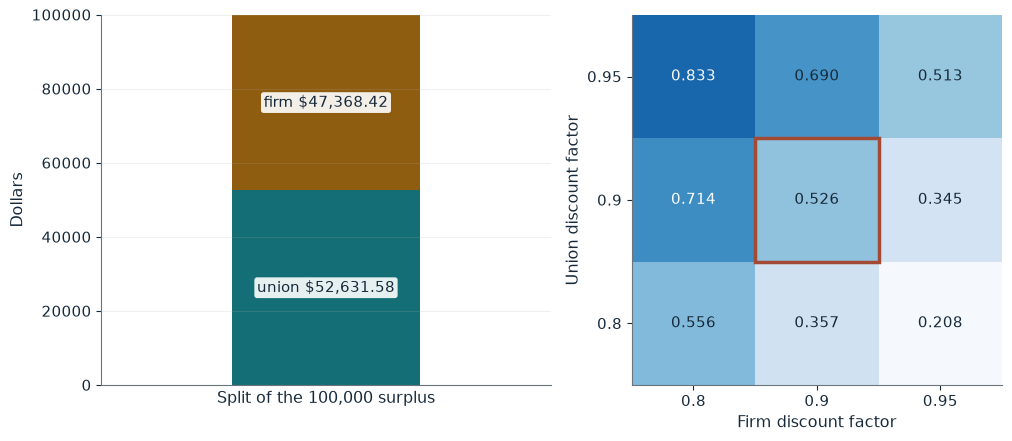

Union share                0.526316
Union keeps                $52,631.58
Firm gets                  $47,368.42
Firm's value of rejecting  $47,368.42

Worked steps:
  1. du x df = 0.9 x 0.9 = 0.8100
  2. x = 0.10 / 0.1900 = 0.526316
  3. Union = 100,000 x 0.526316 = $52,631.58
  4. Firm = 100,000 - $52,631.58 = $47,368.42

x = (1 - 0.9) / (1 - 0.9 x 0.9) = 0.10 / 0.1900 = 0.526316. The union keeps $52,631.58 and offers $47,368.42. If the firm rejects, it proposes tomorrow and keeps its proposer share, worth 0.9 x $52,631.58 = $47,368.42 today, the same as the offer, so it accepts at once.


In [4]:
show(rubinstein_picture(du=0.9, dfirm=0.9))

Change one input, `dfirm`, and hold the others at the book's values:

In [5]:
sweep(rubinstein_picture, 'dfirm', [0.8, 0.9, 0.95], {'du': 0.9}, ['Union share', 'Union keeps', 'Firm gets'])

dfirm | Union share | Union keeps | Firm gets
0.8 | 0.714286 | $71,428.57 | $28,571.43
0.9 | 0.526316 | $52,631.58 | $47,368.42
0.95 | 0.344828 | $34,482.76 | $65,517.24


With equal factors of 0.90 the first proposer keeps \$52,631.58. A less patient firm (0.80) raises the union's take to \$71,428.57; a more patient one (0.95) cuts it to \$34,482.76.

## 3. Shapley value of a venture

$$v(AB)=60,\quad v(AC)=20,\quad v(BC)=30,\quad v(ABC)=120$$

$$(\phi_A,\phi_B,\phi_C)=\left(\frac{130}{3},\frac{145}{3},\frac{85}{3}\right)\approx(43.33,48.33,28.33)$$

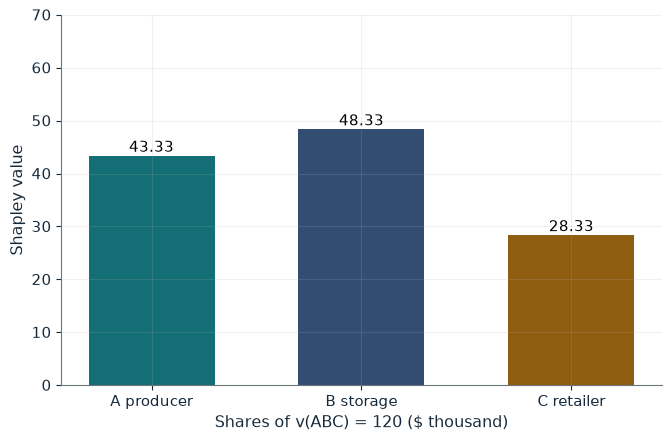

A                                 43.33
B                                 48.33
C                                 28.33
Sum                               120.00
Totals over six orders (A, B, C)  260, 290, 170

Worked steps:
  1. A: 260 / 6 = 43.33
  2. B: 290 / 6 = 48.33
  3. C: 170 / 6 = 28.33
  4. Check: (260 + 290 + 170) / 6 = 120

Over the six arrival orders A adds 0, 0, 60, 90, 20, 90 (total 260), B adds 60, 100, 0, 0, 100, 30 (total 290) and C adds 60, 20, 60, 30, 0, 0 (total 170). Dividing by six gives 43.33, 48.33 and 28.33; the exact shares sum to (260 + 290 + 170) / 6 = 120.


In [6]:
show(shapley_picture(grand=120, game='base'))

Change one input, `grand`, and hold the others at the book's values:

In [7]:
sweep(shapley_picture, 'grand', [100, 120, 150], {'game': 'base'}, ['A', 'B', 'C', 'Sum'])

grand | A | B | C | Sum
100 | 36.67 | 41.67 | 21.67 | 100.00
120 | 43.33 | 48.33 | 28.33 | 120.00
150 | 53.33 | 58.33 | 38.33 | 150.00


B gets the most because it adds the most across arrival orders. If C is a dummy, it gets 0 and A and B take 30 each.

## 4. Bondareva-Shapley theorem: a stable cost-sharing deal

$$\frac{1}{2}(60)+\frac{1}{2}(60)+\frac{1}{2}(60)=90\leq100, \qquad 2(x_A+x_B+x_C)\geq210$$

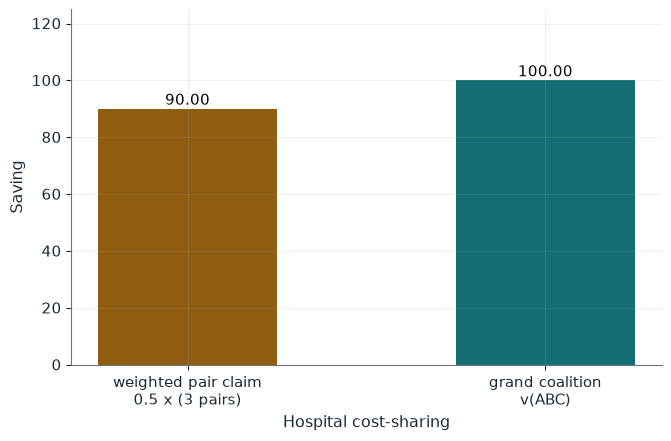

Weighted claim                    90.00
Grand coalition                   100
Core                              nonempty
Equal split                       33.33
Each pair gets under equal split  66.67

Worked steps:
  1. Claim = 0.5 x 60 + 0.5 x 60 + 0.5 x 60 = 90.00
  2. Balanced: 90.00 <= 100
  3. Core nonempty

With weight 1/2 on each pair the claim is 0.5 x 60 x 3 = 90.00 against 100. The claim is within 100, so the core is nonempty: the equal split 33.33 each gives every pair 66.67, more than 60.


In [8]:
show(core_picture(pair=60))

Change one input, `pair`, and hold the others at the book's values:

In [9]:
sweep(core_picture, 'pair', [50, 60, 66.66666666666667, 70], {}, ['Weighted claim', 'Core'])

pair | Weighted claim | Core
50 | 75.00 | nonempty
60 | 90.00 | nonempty
66.66666666666667 | 100.00 | nonempty
70 | 105.00 | empty


The core is nonempty while 1.5 times the pair saving is at most 100: up to 200/3. At 70 it is empty.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

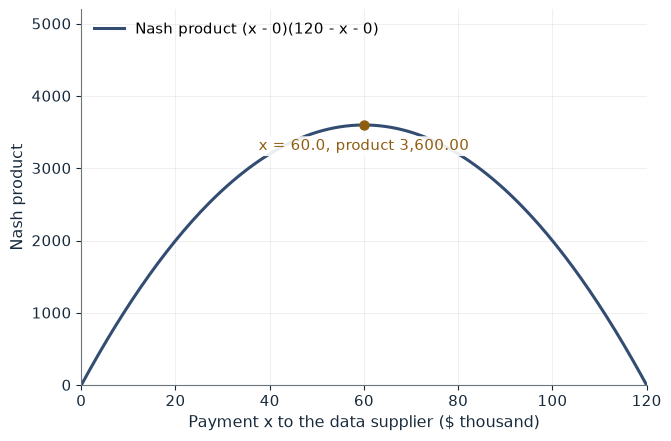

Payment x                      60.0
Supplier gain over its option  60.0
Firm gain over its option      60.0
Nash product                   3,600.00

Worked steps:
  1. x = (120 + 0 - 0) / 2 = 60.0
  2. Supplier gain = 60.0 - 0 = 60.0
  3. Firm gain = 120 - 60.0 - 0 = 60.0
  4. Product = 60.0 x 60.0 = 3,600.00

Maximize (x - 0)(120 - x - 0). The derivative is (120 - x - 0) - (x - 0) = 0, so x = (120 + 0 - 0) / 2 = 60.0. The supplier gains 60.0 - 0 = 60.0 and the firm 120 - 60.0 - 0 = 60.0: the surplus over the two options, 120, is split equally.


In [10]:
show(nash_picture(ds=0, df=0))

## Practice

**1.** With a supplier option of 45 and a firm option of 0, what are the payment and the gains?

<details><summary>Answer</summary>

x = (120 + 45) / 2 = 82.5; gains 37.5 each.

</details>

**2.** With factors 0.90 (union) and 0.95 (firm), what does the union keep?

<details><summary>Answer</summary>

0.05 / 0.145 = 0.3448: \$34,482.76.

</details>

**3.** With v(ABC) = 150, what are the Shapley values?

<details><summary>Answer</summary>

Each gains 10: (53.33, 58.33, 38.33).

</details>